In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/KaggleV2-May-2016.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/KaggleV2-May-2016.csv'

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']


In [ ]:
import os
print(os.listdir('/content'))

['.config', 'KaggleV2-May-2016.csv', 'sample_data']


In [ ]:
df = pd.read_csv('/content/KaggleV2-May-2016.csv')

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

df.head()

Dataset loaded successfully!
Dataset dimensions: (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [ ]:
# 1. Check data types and non-null values
print("DATASET INFORMATION")
df.info()

# 2. Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Check duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# 4. Check target variable distribution
print("\nAPPOINTMENT OUTCOMES")
print(df['No-show'].value_counts())

# 5. Check statistical summary
print("\nSTATISTICAL SUMMARY")
df.describe()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB

MISSING VALUES
PatientId         0
AppointmentID     0
Gender        

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [ ]:
# Investigate age anomalies

print("Patients below age 0:")
print(df[df['Age'] < 0])

print("\nPatients above age 100:")
print(df[df['Age'] > 100])

print("\nNumber of records with negative age:")
print((df['Age'] < 0).sum())

print("\nAge distribution:")
print(df['Age'].describe())

Patients below age 0:
          PatientId  AppointmentID Gender          ScheduledDay  \
99832  4.659432e+14        5775010      F  2016-06-06T08:58:13Z   

             AppointmentDay  Age Neighbourhood  Scholarship  Hipertension  \
99832  2016-06-06T00:00:00Z   -1         ROMÃO            0             0   

       Diabetes  Alcoholism  Handcap  SMS_received No-show  
99832         0           0        0             0      No  

Patients above age 100:
          PatientId  AppointmentID Gender          ScheduledDay  \
58014  9.762948e+14        5651757      F  2016-05-03T09:14:53Z   
63912  3.196321e+13        5700278      F  2016-05-16T09:17:44Z   
63915  3.196321e+13        5700279      F  2016-05-16T09:17:44Z   
68127  3.196321e+13        5562812      F  2016-04-08T14:29:17Z   
76284  3.196321e+13        5744037      F  2016-05-30T09:44:51Z   
90372  2.342836e+11        5751563      F  2016-05-31T10:19:49Z   
97666  7.482346e+14        5717451      F  2016-05-19T07:57:56Z   

    

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
print("Patients below age 0:")
print(df[df['Age'] < 0])

print("\nNumber of negative ages:")
print((df['Age'] < 0).sum())

Patients below age 0:
          PatientId  AppointmentID Gender          ScheduledDay  \
99832  4.659432e+14        5775010      F  2016-06-06T08:58:13Z   

             AppointmentDay  Age Neighbourhood  Scholarship  Hipertension  \
99832  2016-06-06T00:00:00Z   -1         ROMÃO            0             0   

       Diabetes  Alcoholism  Handcap  SMS_received No-show  
99832         0           0        0             0      No  

Number of negative ages:
1


In [ ]:
print(df[df['Age'] > 100][['Age', 'Gender', 'No-show']])

print("\nNumber of patients above 100:")
print((df['Age'] > 100).sum())

       Age Gender No-show
58014  102      F      No
63912  115      F     Yes
63915  115      F     Yes
68127  115      F     Yes
76284  115      F      No
90372  102      F      No
97666  115      F      No

Number of patients above 100:
7


In [ ]:
print(df['Age'].value_counts().sort_index().tail(20))

Age
83     280
84     311
85     275
86     260
87     184
88     126
89     173
90     109
91      66
92      86
93      53
94      33
95      24
96      17
97      11
98       6
99       1
100      4
102      2
115      5
Name: count, dtype: int64


In [ ]:
print(df['Handcap'].value_counts().sort_index())


Handcap
0    108286
1      2042
2       183
3        13
4         3
Name: count, dtype: int64


In [ ]:
print(df[['ScheduledDay', 'AppointmentDay']].head(10))

           ScheduledDay        AppointmentDay
0  2016-04-29T18:38:08Z  2016-04-29T00:00:00Z
1  2016-04-29T16:08:27Z  2016-04-29T00:00:00Z
2  2016-04-29T16:19:04Z  2016-04-29T00:00:00Z
3  2016-04-29T17:29:31Z  2016-04-29T00:00:00Z
4  2016-04-29T16:07:23Z  2016-04-29T00:00:00Z
5  2016-04-27T08:36:51Z  2016-04-29T00:00:00Z
6  2016-04-27T15:05:12Z  2016-04-29T00:00:00Z
7  2016-04-27T15:39:58Z  2016-04-29T00:00:00Z
8  2016-04-29T08:02:16Z  2016-04-29T00:00:00Z
9  2016-04-27T12:48:25Z  2016-04-29T00:00:00Z


In [ ]:
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'], utc=True)
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'], utc=True)

print(df[['ScheduledDay', 'AppointmentDay']].dtypes)

ScheduledDay      datetime64[ns, UTC]
AppointmentDay    datetime64[ns, UTC]
dtype: object


In [ ]:
df['WaitingDays'] = (
    df['AppointmentDay'].dt.normalize() -
    df['ScheduledDay'].dt.normalize()
).dt.days

print(df['WaitingDays'].describe())


count    110527.000000
mean         10.183702
std          15.254996
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: WaitingDays, dtype: float64


In [ ]:
print("Number of negative waiting periods:")
print((df['WaitingDays'] < 0).sum())

print("\nRecords with negative waiting periods:")
print(
    df.loc[df['WaitingDays'] < 0,
           ['ScheduledDay', 'AppointmentDay', 'WaitingDays', 'No-show']]
)

Number of negative waiting periods:
5

Records with negative waiting periods:
                   ScheduledDay            AppointmentDay  WaitingDays No-show
27033 2016-05-10 10:51:53+00:00 2016-05-09 00:00:00+00:00           -1     Yes
55226 2016-05-18 14:50:41+00:00 2016-05-17 00:00:00+00:00           -1     Yes
64175 2016-05-05 13:43:58+00:00 2016-05-04 00:00:00+00:00           -1     Yes
71533 2016-05-11 13:49:20+00:00 2016-05-05 00:00:00+00:00           -6     Yes
72362 2016-05-04 06:50:57+00:00 2016-05-03 00:00:00+00:00           -1     Yes


In [ ]:
print("Scheduled date range:")
print(df['ScheduledDay'].min(), "to", df['ScheduledDay'].max())

print("\nAppointment date range:")
print(df['AppointmentDay'].min(), "to", df['AppointmentDay'].max())

Scheduled date range:
2015-11-10 07:13:56+00:00 to 2016-06-08 20:07:23+00:00

Appointment date range:
2016-04-29 00:00:00+00:00 to 2016-06-08 00:00:00+00:00


In [ ]:
print(pd.crosstab(
    df['Gender'],
    df['No-show'],
    normalize='index'
).round(3))

No-show     No    Yes
Gender               
F        0.797  0.203
M        0.800  0.200


In [ ]:
df.groupby('No-show')['Age'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
No-show,,,,,,,,
No,88208.0,37.79,23.34,-1.0,18.0,38.0,56.0,115.0
Yes,22319.0,34.32,21.97,0.0,16.0,33.0,51.0,115.0


In [ ]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[-2, 17, 30, 45, 60, 75, 120],
    labels=['0-17', '18-30', '31-45', '46-60', '61-75', '76+']
)

print(
    df.groupby('AgeGroup', observed=False)['No-show']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .round(2)
)

AgeGroup
0-17     21.90
18-30    24.62
31-45    21.37
46-60    17.82
61-75    14.86
76+      16.14
Name: No-show, dtype: float64


In [ ]:
df.groupby('No-show')['WaitingDays'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
No-show,,,,,,,,
No,88208.0,8.75,14.55,0.0,0.0,2.0,12.0,179.0
Yes,22319.0,15.83,16.61,-6.0,4.0,11.0,23.0,179.0


In [ ]:
# Preserve the original dataset
df_clean = df.copy()

# Remove impossible age and negative waiting-period records
df_clean = df_clean[
    (df_clean['Age'] >= 0) &
    (df_clean['WaitingDays'] >= 0)
].copy()

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Records removed:", len(df) - len(df_clean))

Original records: 110527
Cleaned records: 110521
Records removed: 6


In [ ]:
df_clean.rename(
    columns={
        'Hipertension': 'Hypertension',
        'Handcap': 'Handicap'
    },
    inplace=True
)

print(df_clean.columns.tolist())

['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'No-show', 'WaitingDays', 'AgeGroup']


In [ ]:
df_clean['No-show'] = df_clean['No-show'].map({
    'Yes': 1,
    'No': 0
})

print(df_clean['No-show'].value_counts())

No-show
0    88207
1    22314
Name: count, dtype: int64


In [ ]:
print(
    df_clean['No-show']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

No-show
0    79.81
1    20.19
Name: proportion, dtype: float64


In [ ]:
print("Unique patients:", df_clean['PatientId'].nunique())
print("Unique appointments:", df_clean['AppointmentID'].nunique())

Unique patients: 62298
Unique appointments: 110521


In [ ]:
appointments_per_patient = df_clean['PatientId'].value_counts()

print(appointments_per_patient.describe().round(2))
print("\nPatients with multiple appointments:",
      (appointments_per_patient > 1).sum())

count    62298.00
mean         1.77
std          1.77
min          1.00
25%          1.00
50%          1.00
75%          2.00
max         88.00
Name: count, dtype: float64

Patients with multiple appointments: 24378


In [ ]:
print(
    pd.crosstab(
        df_clean['SMS_received'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)

No-show          0     1
SMS_received            
0             83.3  16.7
1             72.4  27.6


In [ ]:
df_clean.groupby('SMS_received')['WaitingDays'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
SMS_received,,,,,,,,
0,75039.0,6.01,12.33,0.0,0.0,0.0,6.0,179.0
1,35482.0,19.02,16.98,3.0,7.0,14.0,27.0,179.0


In [ ]:
df_clean['AppointmentWeekday'] = (
    df_clean['AppointmentDay'].dt.day_name()
)

print(
    df_clean.groupby('AppointmentWeekday')['No-show']
    .mean()
    .mul(100)
    .round(2)
)

AppointmentWeekday
Friday       21.23
Monday       20.64
Saturday     23.08
Thursday     19.35
Tuesday      20.09
Wednesday    19.69
Name: No-show, dtype: float64


In [ ]:
df_clean['AppointmentMonth'] = (
    df_clean['AppointmentDay'].dt.month
)

print(
    df_clean.groupby('AppointmentMonth')['No-show']
    .mean()
    .mul(100)
    .round(2)
)

AppointmentMonth
4    19.57
5    20.78
6    18.46
Name: No-show, dtype: float64


In [ ]:
neighbourhood_stats = (
    df_clean.groupby('Neighbourhood')
    .agg(
        Total_Appointments=('No-show', 'count'),
        No_Show_Rate=('No-show', 'mean')
    )
)

neighbourhood_stats['No_Show_Rate'] *= 100

print(
    neighbourhood_stats
    .sort_values('No_Show_Rate', ascending=False)
    .head(10)
    .round(2)
)

                             Total_Appointments  No_Show_Rate
Neighbourhood                                                
ILHAS OCEÂNICAS DE TRINDADE                   2        100.00
SANTOS DUMONT                              1276         28.92
SANTA CECÍLIA                               448         27.46
SANTA CLARA                                 506         26.48
ITARARÉ                                    3514         26.27
JESUS DE NAZARETH                          2853         24.40
HORTO                                       175         24.00
ILHA DO PRÍNCIPE                           2266         23.48
CARATOÍRA                                  2565         23.04
ANDORINHAS                                 2262         23.03


In [ ]:
reliable_neighbourhoods = neighbourhood_stats[
    neighbourhood_stats['Total_Appointments'] >= 100
]

print(
    reliable_neighbourhoods
    .sort_values('No_Show_Rate', ascending=False)
    .head(10)
    .round(2)
)

                   Total_Appointments  No_Show_Rate
Neighbourhood                                      
SANTOS DUMONT                    1276         28.92
SANTA CECÍLIA                     448         27.46
SANTA CLARA                       506         26.48
ITARARÉ                          3514         26.27
JESUS DE NAZARETH                2853         24.40
HORTO                             175         24.00
ILHA DO PRÍNCIPE                 2266         23.48
CARATOÍRA                        2565         23.04
ANDORINHAS                       2262         23.03
PRAIA DO SUÁ                     1288         22.83


In [ ]:
print("Total neighbourhoods:", neighbourhood_stats.shape[0])

print("\nNeighbourhood no-show rate summary:")
print(
    neighbourhood_stats['No_Show_Rate']
    .describe()
    .round(2)
)

Total neighbourhoods: 81

Neighbourhood no-show rate summary:
count     81.00
mean      20.54
std        9.72
min        0.00
25%       17.99
50%       19.76
75%       21.75
max      100.00
Name: No_Show_Rate, dtype: float64


In [ ]:
print(
    neighbourhood_stats['Total_Appointments']
    .describe()
    .round(2)
)

count      81.00
mean     1364.46
std      1369.12
min         1.00
25%       413.00
50%       851.00
75%      2018.00
max      7717.00
Name: Total_Appointments, dtype: float64


In [ ]:
print(
    pd.crosstab(
        df_clean['Hypertension'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)

No-show          0     1
Hypertension            
0             79.1  20.9
1             82.7  17.3


In [ ]:
print(
    pd.crosstab(
        df_clean['Diabetes'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)

No-show      0     1
Diabetes            
0         79.6  20.4
1         82.0  18.0


In [ ]:
print(
    pd.crosstab(
        df_clean['Alcoholism'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)

No-show        0     1
Alcoholism            
0           79.8  20.2
1           79.9  20.1


In [ ]:
print(
    pd.crosstab(
        df_clean['Alcoholism'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)

No-show        0     1
Alcoholism            
0           79.8  20.2
1           79.9  20.1


In [ ]:
print(
    pd.crosstab(
        df_clean['Handicap'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)

No-show      0     1
Handicap            
0         79.8  20.2
1         82.2  17.8
2         79.8  20.2
3         76.9  23.1
4         66.7  33.3


In [ ]:
print(
    df_clean['Handicap']
    .value_counts()
    .sort_index()
)

Handicap
0    108282
1      2040
2       183
3        13
4         3
Name: count, dtype: int64


In [ ]:
print(
    pd.crosstab(
        df_clean['Scholarship'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)

No-show         0     1
Scholarship            
0            80.2  19.8
1            76.3  23.7


In [ ]:
print(
    df_clean['Scholarship']
    .value_counts()
    .sort_index()
)

Scholarship
0    99660
1    10861
Name: count, dtype: int64


In [ ]:
print(
    df_clean['Gender']
    .value_counts()
)

Gender
F    71836
M    38685
Name: count, dtype: int64


In [ ]:
age_waiting_analysis = (
    df_clean.groupby('AgeGroup', observed=True)
    .agg(
        Average_Waiting_Days=('WaitingDays', 'mean'),
        No_Show_Rate=('No-show', 'mean'),
        Total_Appointments=('No-show', 'count')
    )
)

age_waiting_analysis['No_Show_Rate'] *= 100

print(age_waiting_analysis.round(2))

          Average_Waiting_Days  No_Show_Rate  Total_Appointments
AgeGroup                                                        
0-17                      9.61         21.90               27378
18-30                     9.83         24.61               18250
31-45                    10.05         21.37               21953
46-60                    10.44         17.82               23179
61-75                    11.03         14.86               14370
76+                      11.48         16.12                5391


In [ ]:
df_clean['WaitingCategory'] = pd.cut(
    df_clean['WaitingDays'],
    bins=[-1, 0, 7, 14, 30, 60, 180],
    labels=[
        'Same day',
        '1-7 days',
        '8-14 days',
        '15-30 days',
        '31-60 days',
        '61-180 days'
    ]
)

waiting_analysis = (
    df_clean.groupby('WaitingCategory', observed=True)
    .agg(
        Total_Appointments=('No-show', 'count'),
        No_Show_Rate=('No-show', 'mean')
    )
)

waiting_analysis['No_Show_Rate'] *= 100

print(waiting_analysis.round(2))

                 Total_Appointments  No_Show_Rate
WaitingCategory                                  
Same day                      38562          4.65
1-7 days                      32185         24.15
8-14 days                     12025         30.47
15-30 days                    17371         32.59
31-60 days                     8283         34.15
61-180 days                    2095         28.45


In [ ]:
print(
    df_clean.groupby('No-show')['WaitingDays']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

         count   mean  median    std
No-show                             
0        88207   8.75     2.0  14.55
1        22314  15.84    11.0  16.61


In [ ]:
print(
    df_clean.groupby('SMS_received')['WaitingDays']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

              count   mean  median    std
SMS_received                             
0             75039   6.01     0.0  12.33
1             35482  19.02    14.0  16.98


In [ ]:
df_clean['ScheduledWeekday'] = (
    df_clean['ScheduledDay'].dt.day_name()
)

print(
    pd.crosstab(
        df_clean['ScheduledWeekday'],
        df_clean['No-show'],
        normalize='index'
    ).round(3) * 100
)


No-show              0     1
ScheduledWeekday            
Friday            79.5  20.5
Monday            80.2  19.8
Saturday          95.8   4.2
Thursday          79.5  20.5
Tuesday           79.8  20.2
Wednesday         79.9  20.1


In [ ]:
print(
    df_clean['ScheduledWeekday']
    .value_counts()
    .reindex([
        'Monday',
        'Tuesday',
        'Wednesday',
        'Thursday',
        'Friday',
        'Saturday'
    ])
)

ScheduledWeekday
Monday       23084
Tuesday      26167
Wednesday    24259
Thursday     18072
Friday       18915
Saturday        24
Name: count, dtype: int64


In [ ]:
print(
    df_clean['AppointmentWeekday']
    .value_counts()
    .reindex([
        'Monday',
        'Tuesday',
        'Wednesday',
        'Thursday',
        'Friday',
        'Saturday',
        'Sunday'
    ])
)

AppointmentWeekday
Monday       22713.0
Tuesday      25638.0
Wednesday    25866.0
Thursday     17246.0
Friday       19019.0
Saturday        39.0
Sunday           NaN
Name: count, dtype: float64


In [ ]:
df_clean['ScheduledHour'] = (
    df_clean['ScheduledDay'].dt.hour
)

print(
    df_clean['ScheduledHour']
    .value_counts()
    .sort_index()
)

ScheduledHour
6      1577
7     19213
8     15348
9     12823
10    11055
11     8462
12     5422
13     9034
14     9126
15     8079
16     5542
17     2909
18     1340
19      488
20      100
21        3
Name: count, dtype: int64


In [ ]:
hourly_analysis = (
    df_clean.groupby('ScheduledHour')
    .agg(
        Total_Appointments=('No-show', 'count'),
        No_Show_Rate=('No-show', 'mean')
    )
)

hourly_analysis['No_Show_Rate'] *= 100

print(hourly_analysis.round(2))

               Total_Appointments  No_Show_Rate
ScheduledHour                                  
6                            1577         19.15
7                           19213         15.15
8                           15348         18.27
9                           12823         19.70
10                          11055         22.06
11                           8462         22.78
12                           5422         20.36
13                           9034         20.91
14                           9126         22.67
15                           8079         23.18
16                           5542         23.76
17                           2909         24.82
18                           1340         21.27
19                            488         23.36
20                            100         30.00
21                              3         33.33


In [ ]:
monthly_analysis = (
    df_clean.groupby('AppointmentMonth')
    .agg(
        Total_Appointments=('No-show', 'count'),
        No_Show_Rate=('No-show', 'mean')
    )
)

monthly_analysis['No_Show_Rate'] *= 100

print(monthly_analysis.round(2))

                  Total_Appointments  No_Show_Rate
AppointmentMonth                                  
4                               3235         19.57
5                              80836         20.78
6                              26450         18.46


In [ ]:
print(
    df_clean[['Age', 'WaitingDays']]
    .corr()
    .round(3)
)

               Age  WaitingDays
Age          1.000        0.035
WaitingDays  0.035        1.000


In [ ]:
numerical_features = [
    'Age',
    'WaitingDays',
    'Scholarship',
    'Hypertension',
    'Diabetes',
    'Alcoholism',
    'Handicap',
    'SMS_received'
]

print(
    df_clean[numerical_features]
    .corr()
    .round(2)
)

               Age  WaitingDays  Scholarship  Hypertension  Diabetes  \
Age           1.00         0.03        -0.09          0.50      0.29   
WaitingDays   0.03         1.00        -0.03         -0.02     -0.03   
Scholarship  -0.09        -0.03         1.00         -0.02     -0.02   
Hypertension  0.50        -0.02        -0.02          1.00      0.43   
Diabetes      0.29        -0.03        -0.02          0.43      1.00   
Alcoholism    0.10        -0.04         0.04          0.09      0.02   
Handicap      0.08        -0.02        -0.01          0.08      0.06   
SMS_received  0.01         0.40         0.00         -0.01     -0.01   

              Alcoholism  Handicap  SMS_received  
Age                 0.10      0.08          0.01  
WaitingDays        -0.04     -0.02          0.40  
Scholarship         0.04     -0.01          0.00  
Hypertension        0.09      0.08         -0.01  
Diabetes            0.02      0.06         -0.01  
Alcoholism          1.00      0.00         -0

In [ ]:
print(df_clean.columns.tolist())

['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'No-show', 'WaitingDays', 'AgeGroup', 'AppointmentWeekday', 'AppointmentMonth', 'WaitingCategory', 'ScheduledWeekday', 'ScheduledHour']


In [ ]:
model_features = [
    'Gender',
    'Age',
    'Neighbourhood',
    'Scholarship',
    'Hypertension',
    'Diabetes',
    'Alcoholism',
    'Handicap',
    'WaitingDays',
    'AppointmentWeekday',
    'AppointmentMonth',
    'ScheduledWeekday',
    'ScheduledHour'
]

X = df_clean[model_features].copy()

y = df_clean['No-show'].copy()

groups = df_clean['PatientId'].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Unique patients:", groups.nunique())

print("\nFeature columns:")
print(X.columns.tolist())

Feature matrix shape: (110521, 13)
Target shape: (110521,)
Unique patients: 62298

Feature columns:
['Gender', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'WaitingDays', 'AppointmentWeekday', 'AppointmentMonth', 'ScheduledWeekday', 'ScheduledHour']


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training appointments:", len(X_train))
print("Testing appointments:", len(X_test))

print("Training patients:", groups_train.nunique())
print("Testing patients:", groups_test.nunique())

print(
    "Patients appearing in both sets:",
    len(set(groups_train) & set(groups_test))
)

Training appointments: 88441
Testing appointments: 22080
Training patients: 49838
Testing patients: 12460
Patients appearing in both sets: 0


In [ ]:
print("Training target distribution:")
print(
    y_train.value_counts(normalize=True).mul(100).round(2)
)

print("\nTesting target distribution:")
print(
    y_test.value_counts(normalize=True).mul(100).round(2)
)

Training target distribution:
No-show
0    79.88
1    20.12
Name: proportion, dtype: float64

Testing target distribution:
No-show
0    79.54
1    20.46
Name: proportion, dtype: float64


In [ ]:
categorical_features = [
    'Gender',
    'Neighbourhood',
    'Scholarship',
    'Hypertension',
    'Diabetes',
    'Alcoholism',
    'Handicap',
    'AppointmentWeekday',
    'AppointmentMonth',
    'ScheduledWeekday'
]

numerical_features = [
    'Age',
    'WaitingDays',
    'ScheduledHour'
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Gender', 'Neighbourhood', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'AppointmentWeekday', 'AppointmentMonth', 'ScheduledWeekday']

Numerical features:
['Age', 'WaitingDays', 'ScheduledHour']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (88441, 113)
Testing data shape: (22080, 113)


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [ ]:
y_pred = logistic_model.predict(X_test_processed)

y_pred_proba = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred))
print("Number of probability scores:", len(y_pred_proba))

Predictions generated successfully.
Number of predictions: 22080
Number of probability scores: 22080


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy:  0.7899
Precision: 0.3065
Recall:    0.0210
F1-score:  0.0394
ROC-AUC:   0.6657


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nDetailed Results")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Confusion Matrix:
[[17347   215]
 [ 4423    95]]

Detailed Results
True Negatives: 17347
False Positives: 215
False Negatives: 4423
True Positives: 95


In [ ]:
print("Predicted probability distribution:")

print(
    pd.Series(y_pred_proba).describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Predicted probability distribution:
count    22080.000000
mean         0.202423
std          0.093698
min          0.056494
25%          0.140663
50%          0.180028
75%          0.237394
90%          0.320675
95%          0.380701
99%          0.541626
max          0.960635
dtype: float64


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

threshold = 0.30

y_pred_30 = (y_pred_proba >= threshold).astype(int)

print("THRESHOLD:", threshold)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_30))

print("\nPrecision:", precision_score(y_test, y_pred_30))
print("Recall:", recall_score(y_test, y_pred_30))
print("F1-score:", f1_score(y_test, y_pred_30))

THRESHOLD: 0.3
Confusion Matrix:
[[15795  1767]
 [ 3520   998]]

Precision: 0.3609403254972875
Recall: 0.22089420097388224
F1-score: 0.27406288617328023


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_sub_idx, val_idx = next(
    val_splitter.split(X_train, y_train, groups=groups_train)
)

X_train_sub = X_train.iloc[train_sub_idx]
X_val = X_train.iloc[val_idx]

y_train_sub = y_train.iloc[train_sub_idx]
y_val = y_train.iloc[val_idx]

groups_train_sub = groups_train.iloc[train_sub_idx]
groups_val = groups_train.iloc[val_idx]

print("Model training appointments:", len(X_train_sub))
print("Validation appointments:", len(X_val))
print(
    "Patients appearing in both:",
    len(set(groups_train_sub) & set(groups_val))
)

Model training appointments: 70782
Validation appointments: 17659
Patients appearing in both: 0


In [ ]:
X_train_sub_processed = preprocessor.fit_transform(X_train_sub)

X_val_processed = preprocessor.transform(X_val)

print("Training subset:", X_train_sub_processed.shape)
print("Validation set:", X_val_processed.shape)

Training subset: (70782, 113)
Validation set: (17659, 113)


In [ ]:
logistic_model_val = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model_val.fit(
    X_train_sub_processed,
    y_train_sub
)

print("Validation model trained successfully.")

Validation model trained successfully.


In [ ]:
y_val_proba = logistic_model_val.predict_proba(
    X_val_processed
)[:, 1]

print("Validation probabilities generated.")
print("Number of predictions:", len(y_val_proba))

Validation probabilities generated.
Number of predictions: 17659


In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:

    y_val_pred = (y_val_proba >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_val_pred, zero_division=0),
        'Recall': recall_score(y_val, y_val_pred, zero_division=0),
        'F1-score': f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.10     0.2040  0.9779    0.3376
      0.15     0.2415  0.8439    0.3755
      0.20     0.3021  0.5965    0.4011
      0.25     0.3494  0.3763    0.3623
      0.30     0.3625  0.2211    0.2746
      0.35     0.3522  0.1237    0.1831
      0.40     0.3290  0.0641    0.1073
      0.45     0.3267  0.0375    0.0672
      0.50     0.2920  0.0187    0.0352


In [ ]:
# Refit preprocessing on the complete training set
X_train_final = preprocessor.fit_transform(X_train)

# Transform the untouched test set
X_test_final = preprocessor.transform(X_test)

# Train the final Logistic Regression model
final_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

final_logistic_model.fit(X_train_final, y_train)

print("Final Logistic Regression model trained.")

Final Logistic Regression model trained.


In [ ]:
# Generate probability scores
y_test_proba_final = final_logistic_model.predict_proba(
    X_test_final
)[:, 1]

# Apply the validation-selected threshold
final_threshold = 0.20

y_test_pred_final = (
    y_test_proba_final >= final_threshold
).astype(int)

print("Final test predictions generated.")
print("Threshold:", final_threshold)
print("Total predictions:", len(y_test_pred_final))

Final test predictions generated.
Threshold: 0.2
Total predictions: 22080


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("FINAL LOGISTIC REGRESSION RESULTS")
print("----------------------------------")

print(f"Accuracy:  {accuracy_score(y_test, y_test_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_final):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred_final):.4f}")
print(f"F1-score:  {f1_score(y_test, y_test_pred_final):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_proba_final):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_test_proba_final):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_final))

FINAL LOGISTIC REGRESSION RESULTS
----------------------------------
Accuracy:  0.6484
Precision: 0.3126
Recall:    0.5992
F1-score:  0.4109
ROC-AUC:   0.6657
PR-AUC:    0.3099

Confusion Matrix:
[[11610  5952]
 [ 1811  2707]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_final, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [ ]:
rf_test_proba = random_forest_model.predict_proba(
    X_test_final
)[:, 1]

print("Random Forest probability predictions generated.")
print("Number of predictions:", len(rf_test_proba))

Random Forest probability predictions generated.
Number of predictions: 22080


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

rf_test_pred_50 = (rf_test_proba >= 0.50).astype(int)

print("RANDOM FOREST PERFORMANCE (THRESHOLD 0.50)")
print("------------------------------------------")

print(f"Accuracy:  {accuracy_score(y_test, rf_test_pred_50):.4f}")
print(f"Precision: {precision_score(y_test, rf_test_pred_50, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, rf_test_pred_50):.4f}")
print(f"F1-score:  {f1_score(y_test, rf_test_pred_50):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_test_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, rf_test_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred_50))

RANDOM FOREST PERFORMANCE (THRESHOLD 0.50)
------------------------------------------
Accuracy:  0.5878
Precision: 0.3092
Recall:    0.8220
F1-score:  0.4494
ROC-AUC:   0.7314
PR-AUC:    0.3687

Confusion Matrix:
[[9264 8298]
 [ 804 3714]]


In [ ]:
rf_val_proba = random_forest_model.predict_proba(
    X_val_processed
)[:, 1]

print("Random Forest validation probabilities generated.")
print("Number of predictions:", len(rf_val_proba))

Random Forest validation probabilities generated.
Number of predictions: 17659


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_threshold_results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:

    rf_val_pred = (rf_val_proba >= threshold).astype(int)

    rf_threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, rf_val_pred, zero_division=0),
        'Recall': recall_score(y_val, rf_val_pred, zero_division=0),
        'F1-score': f1_score(y_val, rf_val_pred, zero_division=0)
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print(rf_threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.10     0.1996  1.0000    0.3327
      0.15     0.2028  1.0000    0.3373
      0.20     0.2272  0.9957    0.3700
      0.25     0.2672  0.9764    0.4196
      0.30     0.2829  0.9503    0.4360
      0.35     0.2837  0.9356    0.4354
      0.40     0.2851  0.9296    0.4363
      0.45     0.2943  0.9220    0.4462
      0.50     0.3245  0.8766    0.4737


In [ ]:
rf_final_threshold = 0.50

rf_test_pred_final = (
    rf_test_proba >= rf_final_threshold
).astype(int)

print("Final Random Forest test predictions generated.")
print("Threshold:", rf_final_threshold)
print("Total predictions:", len(rf_test_pred_final))

Final Random Forest test predictions generated.
Threshold: 0.5
Total predictions: 22080


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("FINAL RANDOM FOREST RESULTS")
print("----------------------------")

print(f"Accuracy:  {accuracy_score(y_test, rf_test_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, rf_test_pred_final):.4f}")
print(f"Recall:    {recall_score(y_test, rf_test_pred_final):.4f}")
print(f"F1-score:  {f1_score(y_test, rf_test_pred_final):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_test_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, rf_test_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred_final))

FINAL RANDOM FOREST RESULTS
----------------------------
Accuracy:  0.5878
Precision: 0.3092
Recall:    0.8220
F1-score:  0.4494
ROC-AUC:   0.7314
PR-AUC:    0.3687

Confusion Matrix:
[[9264 8298]
 [ 804 3714]]


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

gradient_boosting_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gradient_boosting_model.fit(
    X_train_final.toarray(),
    y_train
)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [ ]:
import numpy as np

# Generate prediction probabilities
gb_test_proba = gradient_boosting_model.predict_proba(
    X_test_final.toarray()
)[:, 1]

# Apply the default classification threshold
gb_test_threshold = 0.50

gb_test_pred = (
    gb_test_proba >= gb_test_threshold
).astype(int)

print("Gradient Boosting test predictions generated.")
print("Threshold:", gb_test_threshold)
print("Total predictions:", len(gb_test_pred))

NameError: name 'gradient_boosting_model' is not defined

In [ ]:
print('gradient_boosting_model' in globals())
print('X_train_final' in globals())
print('X_test_final' in globals())

False
False
False


In [ ]:
import pandas as pd

df = pd.read_csv('/content/KaggleV2-May-2016.csv')

print(df.shape)
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/KaggleV2-May-2016.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving KaggleV2-May-2016.csv to KaggleV2-May-2016.csv


In [ ]:
import pandas as pd

df = pd.read_csv('KaggleV2-May-2016.csv')

print("Dataset shape:", df.shape)
print(df.head())


Dataset shape: (110527, 14)
      PatientId  AppointmentID Gender          ScheduledDay  \
0  2.987250e+13        5642903      F  2016-04-29T18:38:08Z   
1  5.589978e+14        5642503      M  2016-04-29T16:08:27Z   
2  4.262962e+12        5642549      F  2016-04-29T16:19:04Z   
3  8.679512e+11        5642828      F  2016-04-29T17:29:31Z   
4  8.841186e+12        5642494      F  2016-04-29T16:07:23Z   

         AppointmentDay  Age      Neighbourhood  Scholarship  Hipertension  \
0  2016-04-29T00:00:00Z   62    JARDIM DA PENHA            0             1   
1  2016-04-29T00:00:00Z   56    JARDIM DA PENHA            0             0   
2  2016-04-29T00:00:00Z   62      MATA DA PRAIA            0             0   
3  2016-04-29T00:00:00Z    8  PONTAL DE CAMBURI            0             0   
4  2016-04-29T00:00:00Z   56    JARDIM DA PENHA            0             1   

   Diabetes  Alcoholism  Handcap  SMS_received No-show  
0         0           0        0             0      No  
1         

In [ ]:
# Preserve original dataset
df_clean = df.copy()

# Convert date columns
df_clean['ScheduledDay'] = pd.to_datetime(
    df_clean['ScheduledDay'], utc=True
)

df_clean['AppointmentDay'] = pd.to_datetime(
    df_clean['AppointmentDay'], utc=True
)

# Calculate waiting period in calendar days
df_clean['WaitingDays'] = (
    df_clean['AppointmentDay'].dt.normalize() -
    df_clean['ScheduledDay'].dt.normalize()
).dt.days

# Remove invalid age and negative waiting periods
df_clean = df_clean[
    (df_clean['Age'] >= 0) &
    (df_clean['WaitingDays'] >= 0)
].copy()

# Correct column names
df_clean.rename(
    columns={
        'Hipertension': 'Hypertension',
        'Handcap': 'Handicap'
    },
    inplace=True
)

# Encode target variable
df_clean['No-show'] = df_clean['No-show'].map({
    'Yes': 1,
    'No': 0
})

# Create date-based features
df_clean['AppointmentWeekday'] = (
    df_clean['AppointmentDay'].dt.day_name()
)

df_clean['AppointmentMonth'] = (
    df_clean['AppointmentDay'].dt.month
)

df_clean['ScheduledWeekday'] = (
    df_clean['ScheduledDay'].dt.day_name()
)

df_clean['ScheduledHour'] = (
    df_clean['ScheduledDay'].dt.hour
)

print("Cleaning completed.")
print("Cleaned dataset shape:", df_clean.shape)
print("\nTarget distribution:")
print(df_clean['No-show'].value_counts())
print("\nMissing values:", df_clean.isnull().sum().sum())

Cleaning completed.
Cleaned dataset shape: (110521, 19)

Target distribution:
No-show
0    88207
1    22314
Name: count, dtype: int64

Missing values: 0


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Define model features
model_features = [
    'Gender', 'Age', 'Neighbourhood', 'Scholarship',
    'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap',
    'WaitingDays', 'AppointmentWeekday', 'AppointmentMonth',
    'ScheduledWeekday', 'ScheduledHour'
]

X = df_clean[model_features].copy()
y = df_clean['No-show'].copy()
groups = df_clean['PatientId'].copy()

# Split by patient
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

# Verify patient separation
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training patients:", groups_train.nunique())
print("Testing patients:", groups_test.nunique())

print(
    "Overlapping patients:",
    len(set(groups_train) & set(groups_test))
)

Training records: 88441
Testing records: 22080
Training patients: 49838
Testing patients: 12460
Overlapping patients: 0


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Create patient-level validation split
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_sub_idx, val_idx = next(
    val_splitter.split(X_train, y_train, groups=groups_train)
)

X_train_sub = X_train.iloc[train_sub_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_train_sub = y_train.iloc[train_sub_idx].copy()
y_val = y_train.iloc[val_idx].copy()

groups_train_sub = groups_train.iloc[train_sub_idx]
groups_val = groups_train.iloc[val_idx]

# Verify patient separation
print("Training subset:", len(X_train_sub))
print("Validation set:", len(X_val))

print(
    "Overlapping patients:",
    len(set(groups_train_sub) & set(groups_val))
)

# Define feature types
categorical_features = [
    'Gender', 'Neighbourhood', 'Scholarship',
    'Hypertension', 'Diabetes', 'Alcoholism',
    'Handicap', 'AppointmentWeekday',
    'AppointmentMonth', 'ScheduledWeekday'
]

numerical_features = [
    'Age', 'WaitingDays', 'ScheduledHour'
]

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

# Fit ONLY on the training subset
X_train_sub_processed = preprocessor.fit_transform(X_train_sub)

# Transform validation data using the same fitted preprocessor
X_val_processed = preprocessor.transform(X_val)

print("\nProcessed training shape:", X_train_sub_processed.shape)
print("Processed validation shape:", X_val_processed.shape)

Training subset: 70782
Validation set: 17659
Overlapping patients: 0

Processed training shape: (70782, 113)
Processed validation shape: (17659, 113)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

# 1. Logistic Regression
logistic_model_val = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model_val.fit(
    X_train_sub_processed,
    y_train_sub
)

# 2. Random Forest
random_forest_val = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

random_forest_val.fit(
    X_train_sub_processed,
    y_train_sub
)

# 3. Gradient Boosting
gradient_boosting_val = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gradient_boosting_val.fit(
    X_train_sub_processed.toarray(),
    y_train_sub
)

print("All three validation models trained successfully.")

All three validation models trained successfully.


In [ ]:
# Generate no-show probabilities for validation data

logistic_val_proba = logistic_model_val.predict_proba(
    X_val_processed
)[:, 1]

rf_val_proba = random_forest_val.predict_proba(
    X_val_processed
)[:, 1]

gb_val_proba = gradient_boosting_val.predict_proba(
    X_val_processed.toarray()
)[:, 1]

print("Validation predictions generated.")

print("Logistic Regression:", len(logistic_val_proba))
print("Random Forest:", len(rf_val_proba))
print("Gradient Boosting:", len(gb_val_proba))

Validation predictions generated.
Logistic Regression: 17659
Random Forest: 17659
Gradient Boosting: 17659


In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50
]

model_probabilities = {
    'Logistic Regression': logistic_val_proba,
    'Random Forest': rf_val_proba,
    'Gradient Boosting': gb_val_proba
}

results = []

for model_name, probabilities in model_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Precision': precision_score(
                y_val, predictions, zero_division=0
            ),
            'Recall': recall_score(
                y_val, predictions, zero_division=0
            ),
            'F1-score': f1_score(
                y_val, predictions, zero_division=0
            )
        })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

              Model  Threshold  Precision  Recall  F1-score
Logistic Regression       0.10     0.2040  0.9779    0.3376
Logistic Regression       0.15     0.2415  0.8439    0.3755
Logistic Regression       0.20     0.3021  0.5965    0.4011
Logistic Regression       0.25     0.3494  0.3763    0.3623
Logistic Regression       0.30     0.3625  0.2211    0.2746
Logistic Regression       0.35     0.3522  0.1237    0.1831
Logistic Regression       0.40     0.3290  0.0641    0.1073
Logistic Regression       0.45     0.3267  0.0375    0.0672
Logistic Regression       0.50     0.2920  0.0187    0.0352
      Random Forest       0.10     0.1996  1.0000    0.3327
      Random Forest       0.15     0.2027  0.9986    0.3370
      Random Forest       0.20     0.2271  0.9864    0.3693
      Random Forest       0.25     0.2656  0.9501    0.4152
      Random Forest       0.30     0.2794  0.9308    0.4297
      Random Forest       0.35     0.2813  0.9234    0.4312
      Random Forest       0.40     0.282

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

for name, probabilities in model_probabilities.items():

    print(f"\n{name}")
    print("ROC-AUC:",
          round(roc_auc_score(y_val, probabilities), 4))

    print("PR-AUC:",
          round(average_precision_score(y_val, probabilities), 4))


Logistic Regression
ROC-AUC: 0.6631
PR-AUC: 0.3042

Random Forest
ROC-AUC: 0.7322
PR-AUC: 0.3606

Gradient Boosting
ROC-AUC: 0.7363
PR-AUC: 0.3661


In [ ]:
# Refit preprocessing on the complete training set

X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)

# Logistic Regression
final_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

final_logistic_model.fit(X_train_final, y_train)


# Random Forest
final_random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

final_random_forest_model.fit(X_train_final, y_train)


# Gradient Boosting
final_gradient_boosting_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

final_gradient_boosting_model.fit(
    X_train_final.toarray(),
    y_train
)

print("All three final models trained successfully.")

All three final models trained successfully.


In [ ]:
# Logistic Regression
logistic_test_proba = final_logistic_model.predict_proba(
    X_test_final
)[:, 1]

# Random Forest
rf_test_proba = final_random_forest_model.predict_proba(
    X_test_final
)[:, 1]

# Gradient Boosting
gb_test_proba = final_gradient_boosting_model.predict_proba(
    X_test_final.toarray()
)[:, 1]

print("Final test probabilities generated.")

print("Logistic Regression:", len(logistic_test_proba))
print("Random Forest:", len(rf_test_proba))
print("Gradient Boosting:", len(gb_test_proba))

Final test probabilities generated.
Logistic Regression: 22080
Random Forest: 22080
Gradient Boosting: 22080


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Validation-selected thresholds
selected_thresholds = {
    'Logistic Regression': 0.20,
    'Random Forest': 0.50,
    'Gradient Boosting': 0.25
}

test_probabilities = {
    'Logistic Regression': logistic_test_proba,
    'Random Forest': rf_test_proba,
    'Gradient Boosting': gb_test_proba
}

final_results = []

for model_name, probabilities in test_probabilities.items():

    threshold = selected_thresholds[model_name]

    predictions = (probabilities >= threshold).astype(int)

    final_results.append({
        'Model': model_name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1-score': f1_score(y_test, predictions),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'PR-AUC': average_precision_score(y_test, probabilities)
    })

    print(f"\n{'='*45}")
    print(model_name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

final_test_results = pd.DataFrame(final_results)

print("\n\nFINAL TEST PERFORMANCE COMPARISON")
print(final_test_results.round(4).to_string(index=False))


Logistic Regression
Confusion Matrix:
[[11610  5952]
 [ 1811  2707]]

Random Forest
Confusion Matrix:
[[9264 8298]
 [ 804 3714]]

Gradient Boosting
Confusion Matrix:
[[11814  5748]
 [ 1526  2992]]


FINAL TEST PERFORMANCE COMPARISON
              Model  Threshold  Accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
Logistic Regression       0.20    0.6484     0.3126  0.5992    0.4109   0.6657  0.3099
      Random Forest       0.50    0.5878     0.3092  0.8220    0.4494   0.7314  0.3687
  Gradient Boosting       0.25    0.6706     0.3423  0.6622    0.4514   0.7359  0.3740


In [ ]:
import pandas as pd
import numpy as np

feature_importance = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Importance': final_gradient_boosting_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(20).to_string(index=False))

AttributeError: 'HistGradientBoostingClassifier' object has no attribute 'feature_importances_'

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm_result = permutation_importance(
    final_gradient_boosting_model,
    X_test_final.toarray(),
    y_test,
    scoring='average_precision',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("TOP 20 FEATURES")
print(feature_importance.head(20).round(5).to_string(index=False))

TOP 20 FEATURES
                               Feature  Importance     Std
                      num__WaitingDays     0.14274 0.00254
                              num__Age     0.03596 0.00225
                    num__ScheduledHour     0.00772 0.00138
               cat__AppointmentMonth_5     0.00548 0.00112
                     cat__Alcoholism_0     0.00491 0.00186
  cat__Neighbourhood_JESUS DE NAZARETH     0.00220 0.00063
            cat__Neighbourhood_ITARARÉ     0.00220 0.00120
cat__Neighbourhood_ILHA DE SANTA MARIA     0.00211 0.00037
           cat__Neighbourhood_GURIGICA     0.00207 0.00036
      cat__Neighbourhood_SANTOS DUMONT     0.00206 0.00078
        cat__ScheduledWeekday_Thursday     0.00184 0.00037
       cat__AppointmentWeekday_Tuesday     0.00181 0.00069
                    cat__Scholarship_0     0.00169 0.00075
        cat__AppointmentWeekday_Friday     0.00169 0.00031
        cat__AppointmentWeekday_Monday     0.00167 0.00088
         cat__ScheduledWeekday_Tuesday  

In [ ]:
from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

baseline_ap = average_precision_score(y_test, gb_test_proba)

importance_results = []

for feature in X_test.columns:
    drops = []

    for _ in range(5):
        X_permuted = X_test.copy()

        X_permuted[feature] = rng.permutation(
            X_permuted[feature].values
        )

        X_permuted_processed = preprocessor.transform(X_permuted)

        probabilities = final_gradient_boosting_model.predict_proba(
            X_permuted_processed.toarray()
        )[:, 1]

        permuted_ap = average_precision_score(y_test, probabilities)

        drops.append(baseline_ap - permuted_ap)

    importance_results.append({
        'Feature': feature,
        'Importance': np.mean(drops),
        'Std': np.std(drops)
    })

feature_importance_original = pd.DataFrame(importance_results)

feature_importance_original = feature_importance_original.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance_original.round(5).to_string(index=False))

           Feature  Importance     Std
       WaitingDays     0.14044 0.00322
               Age     0.03761 0.00320
     Neighbourhood     0.02341 0.00258
     ScheduledHour     0.00885 0.00119
        Alcoholism     0.00529 0.00067
AppointmentWeekday     0.00527 0.00165
  AppointmentMonth     0.00505 0.00135
  ScheduledWeekday     0.00439 0.00044
       Scholarship     0.00182 0.00171
            Gender     0.00053 0.00031
          Diabetes     0.00045 0.00044
      Hypertension     0.00027 0.00033
          Handicap    -0.00011 0.00023


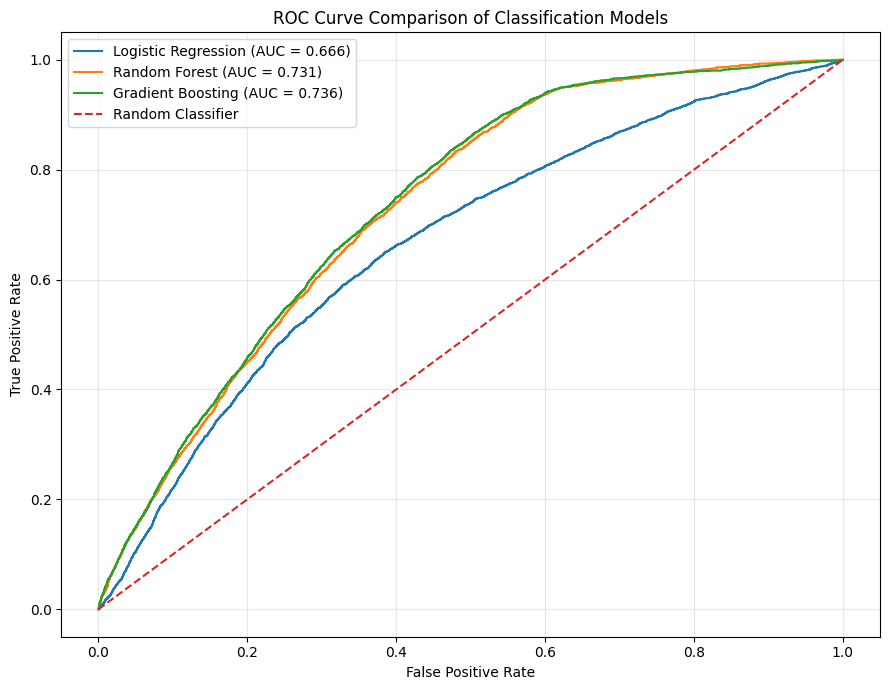

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

models = {
    'Logistic Regression': logistic_test_proba,
    'Random Forest': rf_test_proba,
    'Gradient Boosting': gb_test_proba
}

plt.figure(figsize=(9, 7))

for name, probabilities in models.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Classification Models')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

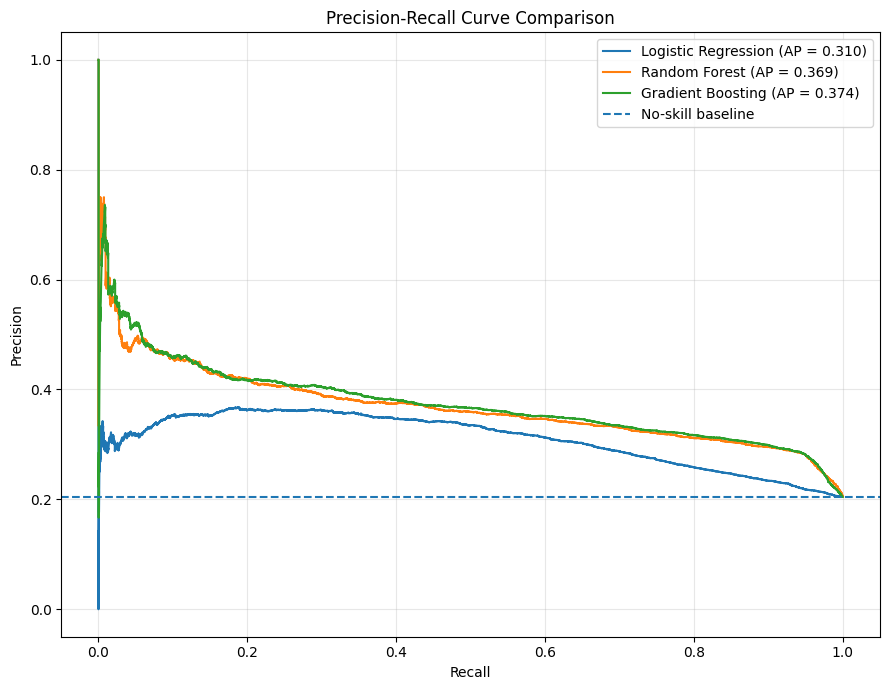

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

models = {
    'Logistic Regression': logistic_test_proba,
    'Random Forest': rf_test_proba,
    'Gradient Boosting': gb_test_proba
}

plt.figure(figsize=(9, 7))

for name, probabilities in models.items():
    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_score = average_precision_score(y_test, probabilities)

    plt.plot(
        recall,
        precision,
        label=f'{name} (AP = {ap_score:.3f})'
    )

plt.axhline(
    y=y_test.mean(),
    linestyle='--',
    label='No-skill baseline'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

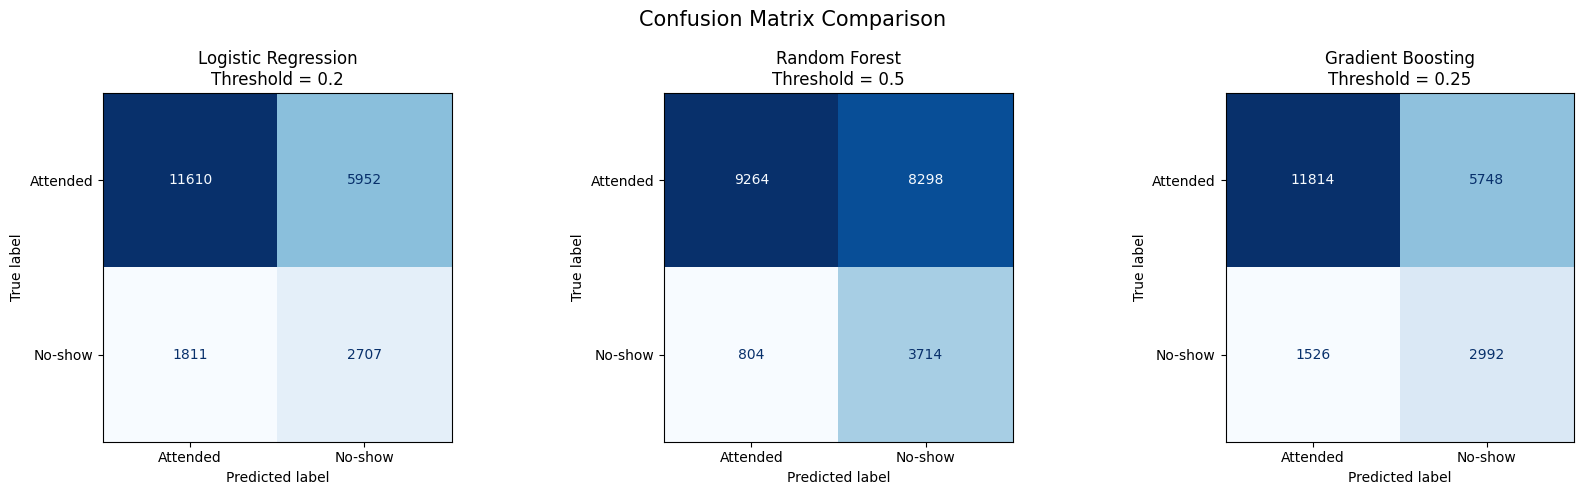

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

models = {
    'Logistic Regression': (logistic_test_proba, 0.20),
    'Random Forest': (rf_test_proba, 0.50),
    'Gradient Boosting': (gb_test_proba, 0.25)
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, (probabilities, threshold)) in zip(axes, models.items()):

    predictions = (probabilities >= threshold).astype(int)

    cm = confusion_matrix(y_test, predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Attended', 'No-show']
    )

    display.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False,
        values_format='d'
    )

    ax.set_title(f'{name}\nThreshold = {threshold}')

plt.suptitle('Confusion Matrix Comparison', fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

models = {
    'Logistic Regression': (logistic_test_proba, 0.20),
    'Random Forest': (rf_test_proba, 0.50),
    'Gradient Boosting': (gb_test_proba, 0.25)
}

comparison_results = []

for name, (probabilities, threshold) in models.items():

    predictions = (probabilities >= threshold).astype(int)

    comparison_results.append({
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'Average Precision': average_precision_score(y_test, probabilities)
    })

model_comparison = pd.DataFrame(comparison_results)

print(model_comparison.round(4).to_string(index=False))

              Model  Threshold  Accuracy  Precision  Recall  F1 Score  ROC-AUC  Average Precision
Logistic Regression       0.20    0.6484     0.3126  0.5992    0.4109   0.6657             0.3099
      Random Forest       0.50    0.5878     0.3092  0.8220    0.4494   0.7314             0.3687
  Gradient Boosting       0.25    0.6706     0.3423  0.6622    0.4514   0.7359             0.3740


In [ ]:
model_comparison.to_csv(
    'model_comparison_results.csv',
    index=False
)

print("Model comparison results saved successfully.")

Model comparison results saved successfully.


In [ ]:
import joblib

joblib.dump(final_logistic_model, 'logistic_regression_model.pkl')
joblib.dump(final_random_forest_model, 'random_forest_model.pkl')
joblib.dump(final_gradient_boosting_model, 'gradient_boosting_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')

print("All models and preprocessing pipeline saved successfully.")

All models and preprocessing pipeline saved successfully.


In [ ]:
import joblib

joblib.dump(final_logistic_model, 'logistic_regression_model.pkl')
joblib.dump(final_random_forest_model, 'random_forest_model.pkl')
joblib.dump(final_gradient_boosting_model, 'gradient_boosting_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')

print("All models and preprocessing pipeline saved successfully.")

All models and preprocessing pipeline saved successfully.


In [ ]:
dashboard_df = X_test.copy()

dashboard_df['Actual_NoShow'] = y_test.values

dashboard_df['LR_Probability'] = logistic_test_proba
dashboard_df['RF_Probability'] = rf_test_proba
dashboard_df['GB_Probability'] = gb_test_proba

dashboard_df['LR_Prediction'] = (
    logistic_test_proba >= 0.20
).astype(int)

dashboard_df['RF_Prediction'] = (
    rf_test_proba >= 0.50
).astype(int)

dashboard_df['GB_Prediction'] = (
    gb_test_proba >= 0.25
).astype(int)

dashboard_df.to_csv(
    'no_show_dashboard_test_data.csv',
    index=False
)

print("Dashboard dataset created successfully.")
print("Shape:", dashboard_df.shape)
print(dashboard_df.head())

Dashboard dataset created successfully.
Shape: (22080, 20)
   Gender  Age    Neighbourhood  Scholarship  Hypertension  Diabetes  \
4       F   56  JARDIM DA PENHA            0             1         1   
6       F   23       GOIABEIRAS            0             0         0   
11      M   29   NOVA PALESTINA            0             0         0   
13      M   28   NOVA PALESTINA            0             0         0   
15      F   15   NOVA PALESTINA            0             0         0   

    Alcoholism  Handicap  WaitingDays AppointmentWeekday  AppointmentMonth  \
4            0         0            0             Friday                 4   
6            0         0            2             Friday                 4   
11           0         0            3             Friday                 4   
13           0         0            1             Friday                 4   
15           0         0            3             Friday                 4   

   ScheduledWeekday  ScheduledHour  Act

In [ ]:
dashboard_df.to_csv(
    'no_show_dashboard_test_data.csv',
    index=False
)

print("Dashboard CSV exported successfully.")

Dashboard CSV exported successfully.
